# XGBoost: interpretazione

Il modello finale viene caricato da MLflow così come l'ha salvato `python -m churn.train_xgboost`: qui non si
riaddestra nulla.

1. **Le due feature costruite** (`mou_vs_lifetime`, `change_mou_pct`): churn per decile, solo sul train.
2. **SHAP beeswarm**: quali variabili muovono il rischio, e in che direzione.
3. **Dependence plot**: la forma dell'effetto di `mou_vs_lifetime`, `change_mou_pct` ed `eqpdays`.
4. **Curva precision-recall** sul test, con la soglia scelta.
5. **Top 10% e top 20%** per score: precision e recall a capacità limitata.

> **Nota: il campione è bilanciato** (~50% di churn: 49.6% sul train). Precision, PR-AUC e Brier score
> dipendono dalla prevalenza, quindi qui non rappresentano quella reale. In produzione, dove il churn è molto più
> raro, alla stessa soglia la precision sarebbe più bassa (più falsi allarmi per ogni churner trovato) e le
> probabilità andrebbero ricalibrate sul tasso reale. Recall e ROC-AUC invece non dipendono dalla prevalenza.

In [1]:
import os
import warnings

# Quieter outputs: no MLflow download bars or hints, no notice about the missing notebook progress widget.
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Found unknown categories")

In [2]:
import mlflow
import numpy as np
import pandas as pd

from churn.config import ROOT, load_config
from churn.data import clean, load_raw, split
from churn.eda import churn_by_bin
from churn.features import add_features_xgb
from churn.model import split_xy, tree_contributions
from churn.plots import (
    plot_beeswarm,
    plot_churn_by_bin,
    plot_dependence,
    plot_pr_curve,
    set_style,
)
from churn.train_logistic import setup_mlflow

cfg = load_config()
set_style()
setup_mlflow(cfg)

# The most recent final run of the experiment; its model is loaded as saved.
run = mlflow.search_runs(experiment_names=[cfg["mlflow"]["experiment"]],
                         filter_string="tags.mlflow.runName = 'xgb_final'",
                         order_by=["start_time DESC"], max_results=1).iloc[0]
pipe = mlflow.sklearn.load_model(f"runs:/{run.run_id}/model")
threshold = float(run["params.threshold"])
run[["params.feature_engineering", "params.threshold", "metrics.test_pr_auc", "metrics.test_roc_auc",
     "metrics.test_brier", "metrics.test_precision", "metrics.test_recall", "metrics.test_f1"]]

params.feature_engineering                  True
params.threshold              0.4305405020713806
metrics.test_pr_auc                     0.691313
metrics.test_roc_auc                    0.699086
metrics.test_brier                      0.219148
metrics.test_precision                  0.598191
metrics.test_recall                     0.780569
metrics.test_f1                         0.677318
Name: 0, dtype: object

In [3]:
# The same split as the training script, so the same hold-out customers.
train, test = split(load_raw(ROOT / cfg["paths"]["raw_data"]), cfg["target"], cfg["test_size"], cfg["seed"])
X_test, y_test = split_xy(test, cfg)

## 1. Le due feature costruite, sul train

Ogni barra è il tasso di churn di un decile della feature (10% dei clienti di train ciascuno); la barra grigia sono
i clienti per cui la feature non si può calcolare (Missing); la linea tratteggiata è il churn medio. Sopra la barra
più rischiosa c'è il suo odds ratio rispetto alla media. Solo train: è la giustificazione dall'EDA, indipendente
dallo screening e dal modello.

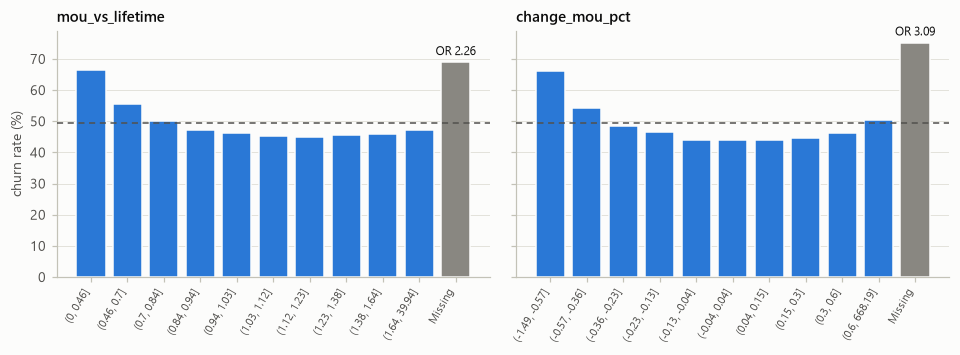

In [4]:
xgb = cfg["xgb"]
formulas = {**xgb["base_feature"], **{name: xgb["candidates"][name] for name in xgb["chosen"]}}
df = add_features_xgb(clean(train, cfg["cleaning"]), formulas)
tables = {name: churn_by_bin(df, name, cfg["target"], cfg["eda"]["n_bins"]) for name in formulas}
fig = plot_churn_by_bin(tables, df[cfg["target"]].mean(), ncols=2)

**Come si legge.** Entrambe hanno un gradino nel decile più basso, cioè nei clienti che stanno usando molto meno
del solito:
- `mou_vs_lifetime` (minuti del mese / media di tutta la vita): sotto il 46% del proprio uso abituale il churn è
  66.5% (OR 2.0), da 0.84 in su resta al 45–47%.
- `change_mou_pct` (variazione rispetto alla media degli ultimi 3 mesi): un calo di oltre il 57% porta al 66%
  (OR 2.0), i clienti stabili sono al 44%, e anche i forti aumenti risalgono al 50%: una forma a V. Il Missing (nessuno
  storico a 3 mesi) è al 75% (OR 3.1).

Le due misurano il calo su orizzonti diversi (tutta la vita contro gli ultimi 3 mesi) e sono poco correlate
(Spearman 0.26). Un rapporto tra due colonne è una cosa che gli alberi approssimano solo con molti split.

## 2. Quali variabili contano: SHAP beeswarm

Valori SHAP esatti (TreeSHAP di XGBoost stesso), calcolati sul test; le colonne one-hot sono sommate per variabile.
Una riga per variabile, ordinate per |SHAP| medio (la più importante in alto). Ogni punto è un cliente:
- **posizione orizzontale**: quanto quella variabile sposta il suo log-odds di churn (a destra = più rischio);
- **colore**: il valore della variabile per quel cliente (blu basso, rosso alto; grigio = categorica o mancante).

Se i punti rossi stanno tutti da un lato, l'effetto ha una direzione; se il colore è mescolato, l'effetto non è
monotono e serve il dependence plot.

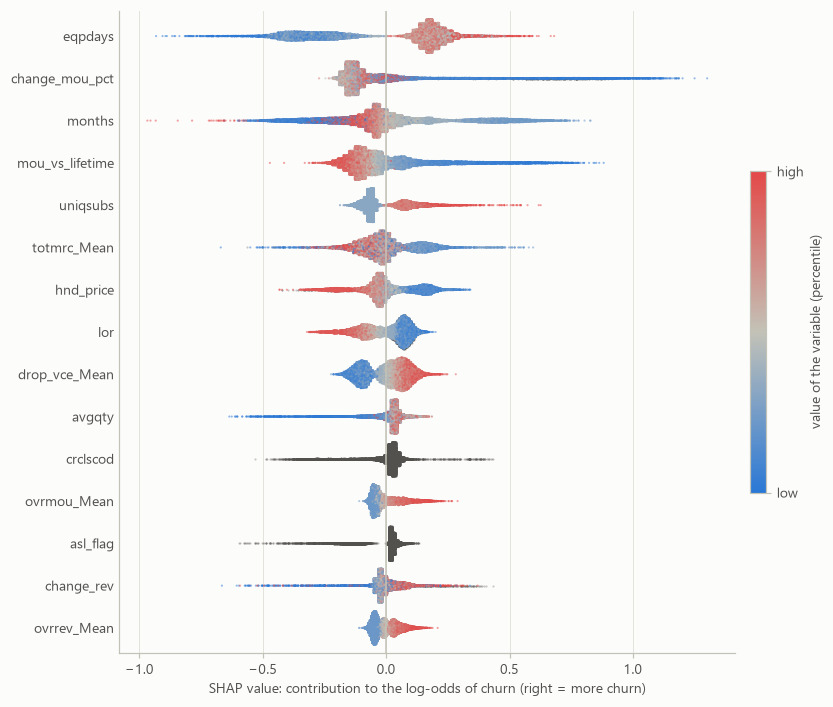

In [5]:
contrib, base = tree_contributions(pipe, X_test)
values = pipe[:-2].transform(X_test)  # the model's inputs before encoding: cleaned values + engineered features
top = list(contrib.abs().mean().sort_values(ascending=False).index[:15])
fig = plot_beeswarm(contrib, values, top, cfg["seed"])

## 3. Dependence plot: la forma dell'effetto

Asse x: il valore della variabile (tagliato all'1°–99° percentile); asse y: il suo valore SHAP; la linea nera è la
media per fascia. Sopra lo zero la variabile alza il rischio, sotto lo abbassa. L'asse y è condiviso, quindi si
confronta anche la forza delle tre variabili. Sono le forme che la logistica non può disegnare con un solo
coefficiente (i suoi residui per fascia lo segnalavano).

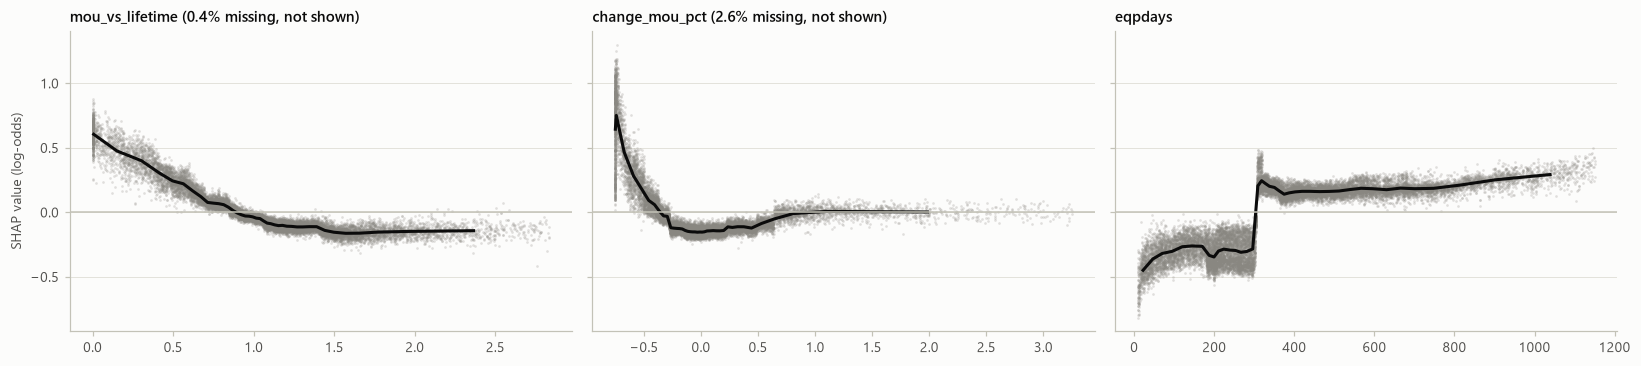

In [6]:
fig = plot_dependence(contrib, values, ["mou_vs_lifetime", "change_mou_pct", "eqpdays"], ncols=3)

## 4. Curva precision-recall sul test

Per ogni soglia: recall (quota dei churner che finiscono nella lista) contro precision (quota della lista che fa
davvero churn). Il punto è la soglia scelta sulle predizioni out-of-fold del train (recall massima con precision
≥ 0.6); la linea tratteggiata è il tasso di churn, cioè la precision di una lista casuale. Sul test la soglia non è
stata toccata: è la stessa valutazione unica dello script, ridisegnata.

Ricorda la nota iniziale: su un campione bilanciato tutta la curva sta più in alto di quanto starebbe sulla
prevalenza reale.

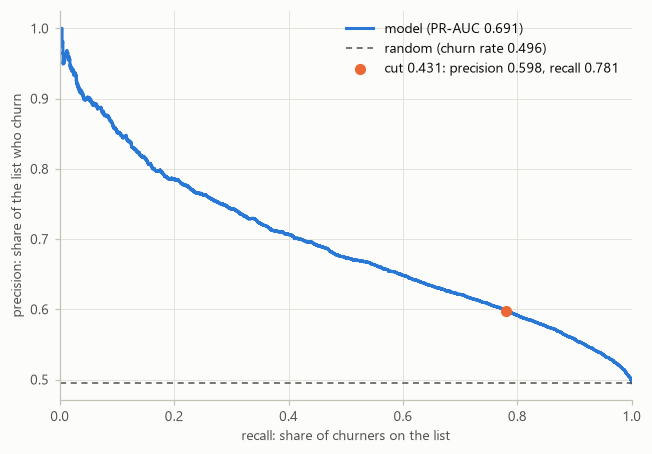

In [7]:
proba = pipe.predict_proba(X_test)[:, 1]
fig = plot_pr_curve(y_test, proba, threshold)

## 5. Scenario a capacità limitata: top 10% e top 20%

Se il team retention può chiamare solo una parte dei clienti, non serve una soglia: si ordina per score e si prende
la testa della lista. **Precision** = quota della lista che fa davvero churn; **recall** = quota di tutti i churner
del test che finiscono nella lista. Riferimento: una lista casuale ha precision pari al tasso di churn (0.50) e
recall pari alla quota chiamata (0.10 / 0.20). Vale la nota iniziale: con la prevalenza reale la precision sarebbe
più bassa, la recall no.

In [8]:
# Churn labels of the test customers, riskiest first.
ranked = y_test.to_numpy()[np.argsort(-proba)]
rows = {}
for share in (0.1, 0.2):
    k = int(share * len(ranked))
    churners = ranked[:k].sum()
    rows[f"top {share:.0%}"] = {"customers": k, "precision": churners / k, "recall": churners / ranked.sum()}
pd.DataFrame(rows).T.astype({"customers": int}).round(3)

,customers,precision,recall
top 10%,2000,0.802,0.162
top 20%,4000,0.743,0.300
